# 1st  — Setup, Load, Label, Merge, Shuffle 

The dataset has **no label column**. We create it ourselves: every article in `True.csv` gets `1` (real), every article in `Fake.csv` gets `0` (fake). Then we stack the two tables and **shuffle**, otherwise all real rows would sit together at the top.

In [1]:
import re, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score, RandomizedSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

print("Setup complete!")

Setup complete!


In [2]:


real = pd.read_csv("True.csv"); real["label"] = 1     # 1 = real
fake = pd.read_csv("Fake.csv"); fake["label"] = 0     # 0 = fake

df = pd.concat([real, fake], ignore_index=True)                    # merge
df = df.sample(frac=1, random_state=42).reset_index(drop=True)     # shuffle

print("Total articles:", len(df))
df.head()

Total articles: 44898


,title,text,subject,date,label
0,BREAKING: GOP Chairman Grassley Has Had Enoug...,"Donald Trump s White House is in chaos, and th...",News,"July 21, 2017",0
1,Failed GOP Candidates Remembered In Hilarious...,Now that Donald Trump is the presumptive GOP n...,News,"May 7, 2016",0
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY...,Mike Pence is a huge homophobe. He supports ex...,News,"December 3, 2016",0
3,California AG pledges to defend birth control ...,SAN FRANCISCO (Reuters) - California Attorney ...,politicsNews,"October 6, 2017",1
4,AZ RANCHERS Living On US-Mexico Border Destroy...,Twisted reasoning is all that comes from Pelos...,politics,"Apr 25, 2017",0


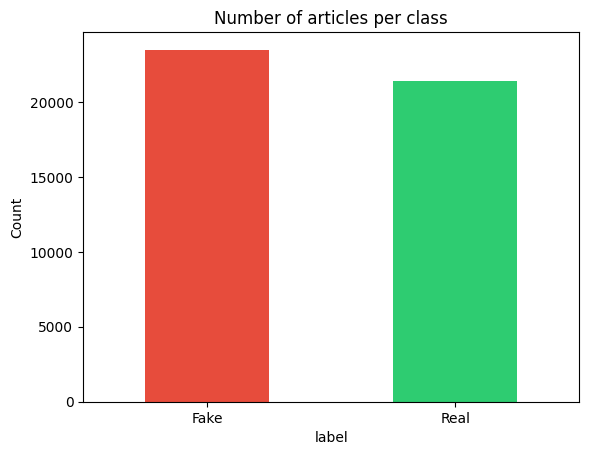

In [3]:
# How balanced is our data?
df["label"].value_counts().plot(kind="bar", color=["#e74c3c", "#2ecc71"])
plt.xticks([0, 1], ["Fake", "Real"], rotation=0)
plt.title("Number of articles per class"); plt.ylabel("Count"); plt.show()

**Observation:** the classes are fairly balanced (≈ 23.5K fake vs ≈ 21.4K real). Because they are not *exactly* equal we will use a **stratified** split later, which keeps the same fake/real ratio in every split.

# 2nd — Data Quality Checks 

>** The sentiment dataset was already clean. Real datasets are not. Before training we must check:
> empty text → duplicates → near-duplicates → length → subject → date.

### 2.1 Empty text rows
A row with no text gives the model nothing to learn from.

In [5]:
#N
df["title"] = df["title"].fillna("")
df["text"]  = df["text"].fillna("")

empty_mask = df["text"].str.strip() == ""
print("Rows with empty text:", empty_mask.sum())
print(df[empty_mask].groupby("label").size())
# .rename({0: "Fake", 1: "Real"}))
# Decision: drop them. They have no body to learn from, and an empty text is
# an easy shortcut (e.g. only one class has them) that does not teach the model anything real.
df = df[~empty_mask].reset_index(drop=True)
print("Rows left:", len(df))

Rows with empty text: 631
label
0    630
1      1
dtype: int64
Rows left: 44267


### 2.2 Exact duplicates
The same article appearing twice is dangerous: one copy can land in **train** and the other in **test**, so the model gets graded on something it has already seen. The accuracy score looks higher than it really is.

We normalise the text first (lowercase + collapse spaces) so tiny formatting differences do not hide duplicates.

In [6]:

norm = df["text"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip() #replace /n/n,tab,or more spaec into one space

extra_copies = norm.duplicated(keep="first")
print("Extra copies of already-seen text :", extra_copies.sum())
print("Titles that repeat                :", df["title"].duplicated().sum())

# Does the SAME text appear under BOTH labels? (that would be a label conflict)
n_labels = df.assign(_n=norm).groupby("_n")["label"].nunique()
print("Texts that appear in both classes :", (n_labels > 1).sum())

# Decision: keep the first copy, drop the rest
df = df[~extra_copies].reset_index(drop=True)
print("Rows left:", len(df))

Extra copies of already-seen text : 5630
Titles that repeat                : 5985
Texts that appear in both classes : 0
Rows left: 38637


### 2.3 Near-duplicates 
Two articles may differ by a single sentence (edited headline, extra line at the end) and still be "the same". We catch them with **TF-IDF + cosine similarity** 
- similarity `1.0` → identical wording, `0.0` → nothing in common.
- We call a pair a near-duplicate if similarity **≥ 0.90**.



In [7]:
# N
THRESH, CHUNK = 0.90, 300

vec = TfidfVectorizer(max_features=20000, stop_words="english", sublinear_tf=True)
X = vec.fit_transform(df["text"])          
y_all = df["label"].to_numpy()

pairs = []
for start in range(0, X.shape[0], CHUNK):
    sims = (X[start:start + CHUNK] @ X.T).tocoo()           
    a = sims.row + start; b = sims.col
    keep = (sims.data >= THRESH) & (b > a)                  
    pairs += list(zip(a[keep], b[keep], sims.data[keep]))

nd = pd.DataFrame(pairs, columns=["row_a", "row_b", "cosine"])
nd["label_a"] = y_all[nd["row_a"]] if len(nd) else []
nd["label_b"] = y_all[nd["row_b"]] if len(nd) else []

print("Near-duplicate pairs (cosine >= 0.90):", len(nd))
if len(nd):
    print("Pairs whose two articles have DIFFERENT labels:", (nd.label_a != nd.label_b).sum())
nd.sort_values("cosine", ascending=False).head(5)

Near-duplicate pairs (cosine >= 0.90): 1363
Pairs whose two articles have DIFFERENT labels: 1


,row_a,row_b,cosine,label_a,label_b
371,4705,37564,1.0,1,1
595,6170,27917,1.0,1,1
21,786,30961,1.0,1,1
999,14557,27253,1.0,1,1
18,632,35557,1.0,1,1


In [8]:
#N
to_drop = set(nd["row_b"]) if len(nd) else set()
df = df.drop(index=list(to_drop)).reset_index(drop=True)
print("Dropped near-duplicates:", len(to_drop), "| Rows left:", len(df))
print(df["label"].value_counts().rename({0: "Fake", 1: "Real"}))

Dropped near-duplicates: 519 | Rows left: 38118
label
Real    20833
Fake    17285
Name: count, dtype: int64


**✍️ Decision & reason :**
- **Empty text** → dropped (nothing to learn from).
- **Exact duplicates** → dropped, keep the first copy. Reason: duplicates leak between train and test and increase the score.
- **Near-duplicates (≥ 0.90)** → dropped, keep one of each pair. Reason: same leakage problem, just with slightly edited text.
- Cross-label duplicates (if any) are a red flag: the same text cannot be both real and fake.

### 2.4 Article length per class

         count   mean    std   min    5%    25%    50%    75%    95%     max
label                                                                       
Fake   17285.0  424.8  349.2   1.0  51.0  278.0  377.0  503.0  845.8  8135.0
Real   20833.0  383.1  271.3  22.0  66.0  148.0  358.0  519.0  888.0  5172.0


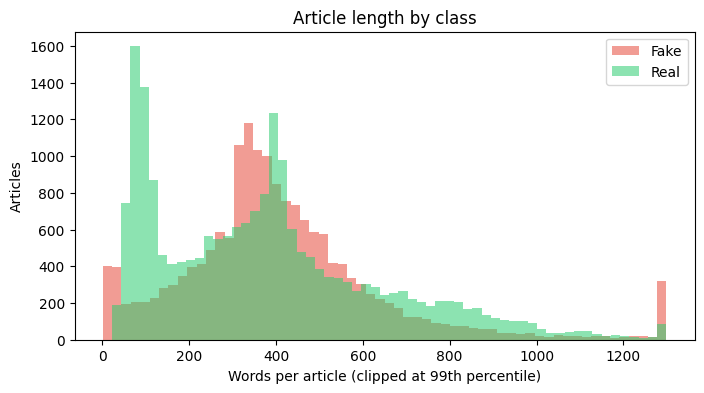

In [9]:
#N
df["n_words"] = df["text"].str.split().str.len()

print(df.groupby("label")["n_words"].describe(percentiles=[.05, .25, .5, .75, .95]).rename({0: "Fake", 1: "Real"}).round(1))

clip = df["n_words"].quantile(0.99)           
plt.figure(figsize=(8, 4))
for lb, name, color in [(0, "Fake", "#e74c3c"), (1, "Real", "#2ecc71")]:
    plt.hist(df.loc[df.label == lb, "n_words"].clip(upper=clip), bins=60, alpha=0.55, label=name, color=color)
plt.xlabel("Words per article (clipped at 99th percentile)"); plt.ylabel("Articles")
plt.title("Article length by class"); plt.legend(); plt.show()

### 2.5 Subject per class

In [10]:
# N
subject_table = pd.crosstab(df["subject"], df["label"].map({0: "Fake", 1: "Real"}), margins=True)
subject_table

label,Fake,Real,All
subject,,,
Government News,882,0,882
Middle-east,382,0,382
News,9049,0,9049
US_News,388,0,388
left-news,2369,0,2369
politics,4215,0,4215
politicsNews,0,11003,11003
worldnews,0,9830,9830
All,17285,20833,38118


>## If every subject belongs to only one class, then `subject` alone can reveal the answer. 
### 2.6 Date per class

Unparseable dates: 27552
label
Fake     6719
Real    20833
dtype: int64

Date range per class:
             min        max
label                      
Fake  2015-05-01 2017-12-31
Real         NaT        NaT


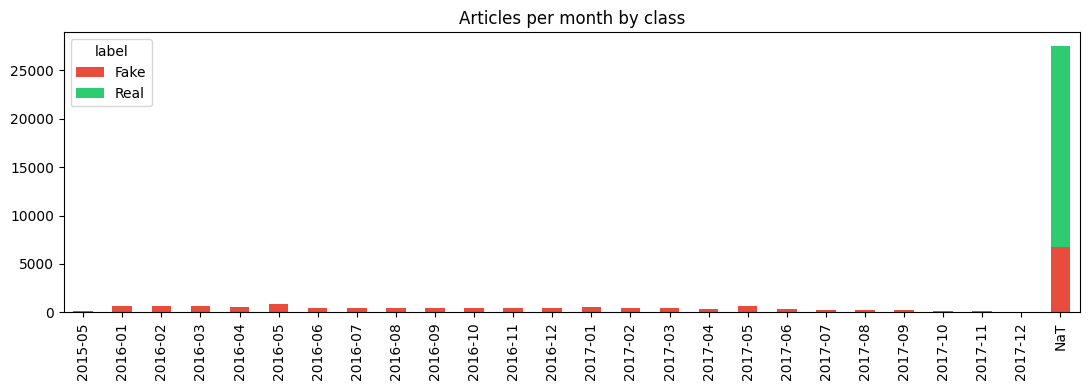

In [11]:
# N
d = pd.to_datetime(df["date"], errors="coerce")        
print("Unparseable dates:", d.isna().sum())
print(df[d.isna()].groupby("label").size().rename({0: "Fake", 1: "Real"}))

print("\nDate range per class:")
print(df.assign(d=d).groupby("label")["d"].agg(["min", "max"]).rename({0: "Fake", 1: "Real"}))

by_month = pd.crosstab(d.dt.to_period("M").astype(str), df["label"].map({0: "Fake", 1: "Real"}))
by_month.plot(kind="bar", stacked=True, figsize=(11, 4), color=["#e74c3c", "#2ecc71"])
plt.title("Articles per month by class"); plt.xlabel(""); plt.tight_layout(); plt.show()

# 3rd — Baseline: TF-IDF + Logistic Regression 

**Pipeline → fit → classification report → confusion matrix**.
The only differences: the feature is **title + text** joined together, and the split is **stratified**.

===== Baseline (title + text) =====
Accuracy: 98.8851%

              precision    recall  f1-score   support

        Fake     0.9927    0.9826    0.9876      3457
        Real     0.9857    0.9940    0.9898      4167

    accuracy                         0.9889      7624
   macro avg     0.9892    0.9883    0.9887      7624
weighted avg     0.9889    0.9889    0.9888      7624



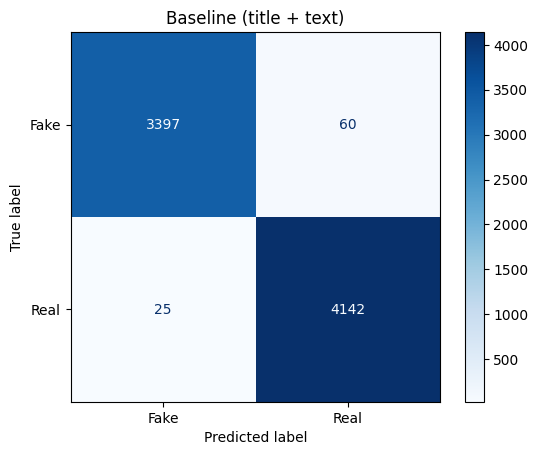

In [12]:
df["content"] = df["title"] + " " + df["text"]

def evaluate(X, y, name, test_size=0.2):
    # stratified split -> same fake/real ratio in train and test
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=test_size, stratify=y, random_state=42)
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", sublinear_tf=True, max_features=50000)),
        ("clf", LogisticRegression(max_iter=1000)),
    ]).fit(Xtr, ytr)
    pred = pipe.predict(Xte)
    print(f"===== {name} =====")
    print(f"Accuracy: {accuracy_score(yte, pred):.4%}\n")
    print(classification_report(yte, pred, target_names=["Fake", "Real"], digits=4))
    ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=["Fake", "Real"]).plot(cmap="Blues")
    plt.title(name); plt.show()
    return pipe, accuracy_score(yte, pred)

baseline, acc_baseline = evaluate(df["content"], df["label"], "Baseline (title + text)")

# 4th -->Leakeage Invension

> **Data leakage** = the model finds a shortcut that has nothing to do with the real task. It scores very high, but would fail on news from another source.

My plan:
1. Look at the top-weighted features (like "What did the model learn?" in the class notebook).
2. Search for source-identifying strings (datelines, outlet names, social-media boilerplate).
3. Train a model on `subject` **only**.
4. Strip the leaks, drop `subject` and `date`, retrain.

### 4.1 Top-weighted features

In [13]:
# N
names = baseline.named_steps["tfidf"].get_feature_names_out()
w = baseline.named_steps["clf"].coef_[0]
order = np.argsort(w)

print("Strongest FAKE features:", [names[i] for i in order[:25]])
print("\n Strongest REAL features:", [names[i] for i in order[-25:][::-1]])

Strongest FAKE features: ['video', 'image', 'featured', 'just', 'read', 'gop', 'getty', 'watch', 'com', 'america', 'obama', 'images', 'hillary', 'pic', 'mr', 'breaking', 'like', 'https', 'rep', 'sen', 'american', 'didn', 'wire', 'fact', 'isn']

 Strongest REAL features: ['reuters', 'said', 'washington', 'wednesday', 'tuesday', 'thursday', 'republican', 'nov', 'friday', 'minister', 'monday', 'spokesman', 'presidential', 'comment', 'reporters', 'democratic', 'statement', 'representatives', 'told', 'year', 'london', 'rival', 'month', 'including', 'president']




### 4.2 Search for source-identifying strings

In [14]:
# N
patterns = {
    "'(Reuters)' dateline":  r"\(reuters\)",
    "word 'Reuters'":        r"reuters",
    "'featured image'":      r"featured image",
    "'image via'":           r"image via",
    "'pic.twitter.com'":     r"pic\.twitter\.com",
    "'Getty'":               r"getty",
    "any URL (http)":        r"https?://",
    "an @handle":            r"@\w+",
    "'Follow us / Share'":   r"follow us|share this|like us on facebook",
}
rows = {name: df.groupby("label")["text"].apply(lambda s, p=p: s.str.contains(p, case=False, regex=True).mean())
        for name, p in patterns.items()}
leak_table = pd.DataFrame(rows).T.rename(columns={0: "Fake", 1: "Real"})
(leak_table * 100).round(1).astype(str) + " %"

label,Fake,Real
'(Reuters)' dateline,0.0 %,99.2 %
word 'Reuters',1.3 %,99.8 %
'featured image',47.2 %,0.0 %
'image via',36.3 %,0.0 %
'pic.twitter.com',15.4 %,0.0 %
'Getty',23.5 %,0.0 %
any URL (http),14.2 %,0.0 %
an @handle,27.1 %,1.3 %
'Follow us / Share',0.3 %,0.0 %


A pattern that appears in a big share of **one** class and almost never in the other is a leak. Add any new string you spot in 4.1 to the `patterns` dict and look again.

### 4.3 A model that only sees `subject`
If `subject` alone gets a high score, then `subject` is a shortcut.

===== Subject-only model =====
Accuracy: 100.0000%

              precision    recall  f1-score   support

        Fake     1.0000    1.0000    1.0000      3457
        Real     1.0000    1.0000    1.0000      4167

    accuracy                         1.0000      7624
   macro avg     1.0000    1.0000    1.0000      7624
weighted avg     1.0000    1.0000    1.0000      7624



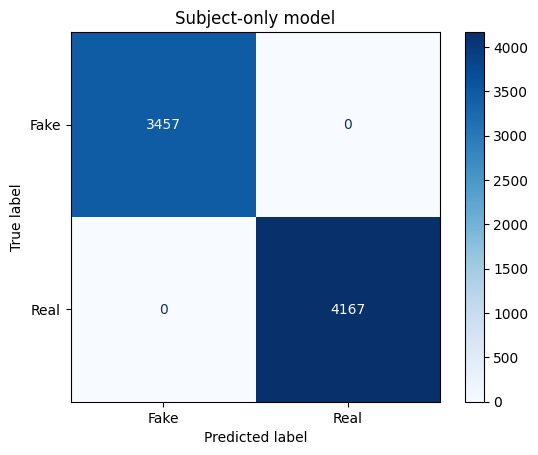

In [15]:
# N
subject_model, acc_subject = evaluate(df["subject"], df["label"], "Subject-only model")

### 4.4 Strip the leaks, drop `subject` and `date`, retrain
We remove the source signatures from **both** `title` and `text`, and we do not use `subject` or `date` at all.

In [16]:
# N
LEAK_REGEX = "|".join([
    r"^[A-Z0-9 ,.'/\-]{0,60}\(Reuters\)\s*-?\s*",   # WASHINGTON (Reuters) -  (dateline at the very start)
    r"\(?reuters\)?",                              # the word Reuters
    r"featured image.*",                           # 'Featured image via ...'
    r"image via.*",
    r"pic\.twitter\.com/\S+",                      # tweet picture links
    r"https?://\S+",                               # URLs
    r"\b(getty|twitter|facebook)\b",               # outlet / platform names
])

def strip_leaks(s):
    s = re.sub(LEAK_REGEX, " ", s, flags=re.I)
    return re.sub(r"\s+", " ", s).strip()

print("BEFORE:", df["text"].iloc[0][:200].replace("\n", " "))
print("AFTER :", strip_leaks(df["text"].iloc[0])[:200])

df["title_c"]   = df["title"].apply(strip_leaks)
df["text_c"]    = df["text"].apply(strip_leaks)
df["content_c"] = df["title_c"] + " " + df["text_c"]      # subject and date are NOT included

BEFORE: Donald Trump s White House is in chaos, and they are trying to cover it up. Their Russia problems are mounting by the hour, and they refuse to acknowledge that there are problems surrounding all of th
AFTER : Donald Trump s White House is in chaos, and they are trying to cover it up. Their Russia problems are mounting by the hour, and they refuse to acknowledge that there are problems surrounding all of th


===== Cleaned (no leaks, no subject/date) =====
Accuracy: 98.0456%

              precision    recall  f1-score   support

        Fake     0.9853    0.9714    0.9783      3457
        Real     0.9765    0.9880    0.9822      4167

    accuracy                         0.9805      7624
   macro avg     0.9809    0.9797    0.9803      7624
weighted avg     0.9805    0.9805    0.9804      7624



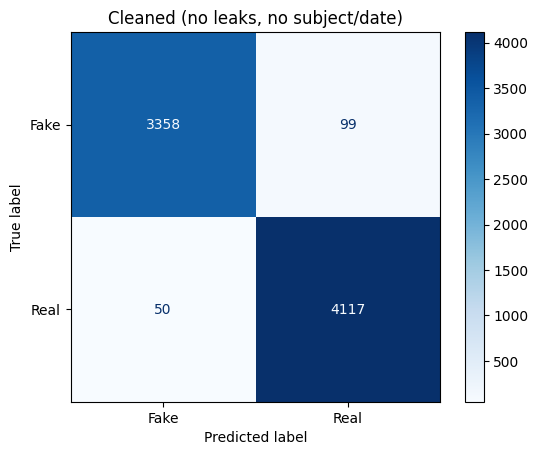

Baseline : 98.885%
Subject  : 100.000%   <- a model that never read a single sentence
Cleaned  : 98.046%   <- the honest score


In [17]:
# N
cleaned, acc_cleaned = evaluate(df["content_c"], df["label"], "Cleaned (no leaks, no subject/date)")

print(f"Baseline : {acc_baseline:.3%}")
print(f"Subject  : {acc_subject:.3%}   <- a model that never read a single sentence")
print(f"Cleaned  : {acc_cleaned:.3%}   <- the honest score")

**What to write:** the drop from *baseline* to *cleaned* is the part of the score that came from shortcuts. The cleaned score is the one you can trust. Re-run 4.1 on the `cleaned` model; if you still see outlet names, add them to `LEAK_REGEX` and run again.



# 5th— Compare Classifiers with Cross-Validation

|

,F1 mean,F1 std,train time (s)
model,,,
Logistic Regression,0.9823,0.0016,24.1815
Linear SVM,0.9889,0.0007,25.1905
Naive Bayes,0.9427,0.0023,24.3607


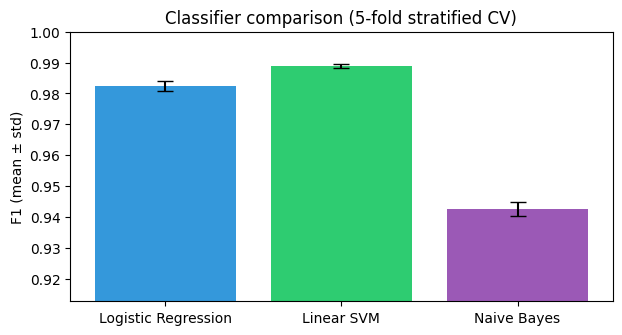

 Best by mean F1: Linear SVM


In [20]:
# 
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM":          LinearSVC(),
    "Naive Bayes":         MultinomialNB(),
}

rows = []
for name, clf in models.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(stop_words="english", sublinear_tf=True, max_features=50000)),
                     ("clf", clf)])
    r = cross_validate(pipe, df["content_c"], df["label"], cv=cv, scoring="f1", n_jobs=-1)
    rows.append({"model": name, "F1 mean": r["test_score"].mean(), "F1 std": r["test_score"].std(),
                 "train time (s)": r["fit_time"].mean()})

results = pd.DataFrame(rows).set_index("model")
display(results.round(4))

plt.figure(figsize=(7, 3.5))
plt.bar(results.index, results["F1 mean"], yerr=results["F1 std"], capsize=6, color=["#3498db", "#2ecc71", "#9b59b6"])
plt.ylim(max(0, results["F1 mean"].min() - 0.03), 1.0); plt.ylabel("F1 (mean ± std)")
plt.title("Classifier comparison (5-fold stratified CV)"); plt.show()

best_name = results["F1 mean"].idxmax()
print(" Best by mean F1:", best_name)

# 6th — Hyper-parameter Tuning & Feature-set Experiment 




In [21]:
# 
pipe = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", sublinear_tf=True)),
    ("clf", models[best_name]),
])

reg_param = "clf__alpha" if best_name == "Naive Bayes" else "clf__C"     
param_grid = {
    "tfidf__ngram_range":  [(1, 1), (1, 2)],
    "tfidf__max_features": [30000, 100000],
    "tfidf__min_df":       [2, 5],
    "tfidf__max_df":       [0.8, 0.95],
    reg_param:             [0.1, 0.5, 1, 5],
}

search = RandomizedSearchCV(pipe, param_grid, n_iter=10, cv=3, scoring="f1", n_jobs=-1, random_state=42, verbose=1)
t0 = time.time(); search.fit(df["content_c"], df["label"])

print(f" {time.time() - t0:.0f}s")
print("Best parameters:", search.best_params_)
print(f"Best CV F1     : {search.best_score_:.4f}")

Fitting 3 folds for each of 10 candidates, totalling 30 fits
 314s
Best parameters: {'tfidf__ngram_range': (1, 2), 'tfidf__min_df': 2, 'tfidf__max_features': 100000, 'tfidf__max_df': 0.95, 'clf__C': 5}
Best CV F1     : 0.9906


,F1 mean,F1 std
features,,
Title only,0.9451,0.0019
Text only,0.9886,0.0009
Title + Text,0.9911,0.0006


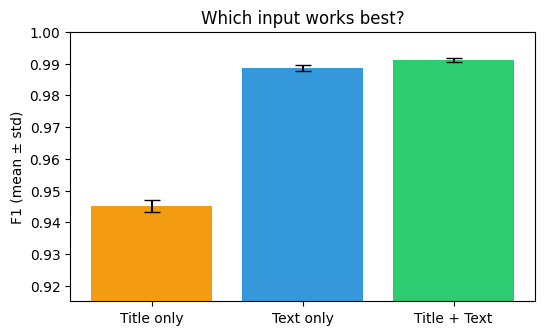

In [22]:

rows = []
for col, label in [("title_c", "Title only"), ("text_c", "Text only"), ("content_c", "Title + Text")]:
    s = cross_val_score(search.best_estimator_, df[col], df["label"], cv=cv, scoring="f1", n_jobs=-1)
    rows.append({"features": label, "F1 mean": s.mean(), "F1 std": s.std()})

feat = pd.DataFrame(rows).set_index("features")
display(feat.round(4))

plt.figure(figsize=(6, 3.5))
plt.bar(feat.index, feat["F1 mean"], yerr=feat["F1 std"], capsize=6, color=["#f39c12", "#3498db", "#2ecc71"])
plt.ylim(max(0, feat["F1 mean"].min() - 0.03), 1.0); plt.ylabel("F1 (mean ± std)")
plt.title("Which input works best?"); plt.show()